# Statistical and Advanced Business Analysis

## Objective

I statistically evaluate the strongest patterns identified during exploratory analysis and perform advanced customer-retention and product-combination analysis.

The analysis focuses on statistical significance, effect size, business relevance, and analytical limitations. Statistical association is not interpreted as proof of causation.

## Advanced Business Questions

1. Is discount significantly associated with sales-line profitability?
2. Does the probability of a loss-making transaction change across discount bands?
3. Are profitability differences across discount bands statistically significant and practically meaningful?
4. Do profit outcomes differ significantly across major product categories?
5. How does customer retention change across acquisition cohorts?
6. Which product combinations appear together most frequently?
7. Which product pairs demonstrate meaningful support, confidence, and lift?
8. Which EDA findings remain strong after statistical and advanced analysis?

## 1. Environment and Project Paths

I configure the statistical-analysis environment and locate the cleaned analytical dataset using a relative project path.

In [1]:
from pathlib import Path
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats


current_folder = Path.cwd()

if current_folder.name.lower() == "notebooks":
    project_folder = current_folder.parent
else:
    project_folder = current_folder

processed_data_folder = project_folder / "data" / "processed"

if not processed_data_folder.exists():
    raise FileNotFoundError(
        f"Processed data folder was not found: "
        f"{processed_data_folder}"
    )


pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.4f}".format)

sns.set_theme(
    style="whitegrid",
    context="notebook"
)

plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["figure.dpi"] = 120
plt.rcParams["axes.titleweight"] = "bold"


print("Current folder:", current_folder.name)
print("Project folder:", project_folder.name)
print("Processed data folder:", processed_data_folder)
print("Processed folder exists:", processed_data_folder.exists())

Current folder: notebooks
Project folder: ecommerce_sales_customer_profitability_analytics
Processed data folder: C:\Users\niles\Nilesh\ecommerce_sales_customer_profitability_analytics\data\processed
Processed folder exists: True


## 2. Load and Validate Analytical Data

I load the cleaned Orders dataset and confirm the analytical grain and required fields before running statistical tests.

**Customer identity note:** Customer-level and cohort analyses use the name-based surrogate `customer_key` established during data cleaning because raw Customer IDs contain geography-specific variants. These results represent named customer entities within this dataset, not independently verified real-world identities.

In [2]:
orders = pd.read_csv(
    processed_data_folder / "orders_cleaned.csv",
    encoding="utf-8-sig",
    dtype={"postal_code": "string"},
    parse_dates=["order_date", "ship_date"],
    low_memory=False
)


required_columns = {
    "row_id",
    "order_key",
    "order_date",
    "customer_key",
    "product_id",
    "product_name",
    "category",
    "sub_category",
    "sales",
    "profit",
    "discount",
    "line_profit_margin"
}

missing_columns = sorted(
    required_columns.difference(orders.columns)
)

if missing_columns:
    raise KeyError(
        f"Required columns are missing: {missing_columns}"
    )

if not orders["row_id"].is_unique:
    raise ValueError(
        "Row ID is not unique."
    )


analysis_scope = pd.DataFrame({
    "Metric": [
        "Sales Lines",
        "Analytical Orders",
        "Customers",
        "Products",
        "Order Date Range"
    ],
    "Value": [
        f"{len(orders):,}",
        f"{orders['order_key'].nunique():,}",
        f"{orders['customer_key'].nunique():,}",
        f"{orders['product_id'].nunique():,}",
        (
            f"{orders['order_date'].min():%Y-%m-%d} "
            f"to {orders['order_date'].max():%Y-%m-%d}"
        )
    ]
})

display(analysis_scope)

,Metric,Value
0,Sales Lines,"51,290"
1,Analytical Orders,"25,739"
2,Customers,796
3,Products,"3,788"
4,Order Date Range,2012-01-01 to 2015-12-31


## 3. Statistical Framework

I use a significance level of 5% and report effect sizes alongside p-values.

- **Significance level:** α = 0.05
- **p-value below α:** Evidence against the null hypothesis
- **Effect size:** Measures the practical strength of the relationship
- **Interpretation:** Statistical association does not establish causation

Because the data-quality audit identified valid outliers and skewed financial distributions, I use rank-based and contingency-table methods that do not require normally distributed outcomes.

In [3]:
SIGNIFICANCE_LEVEL = 0.05


statistical_data = orders[
    [
        "row_id",
        "order_key",
        "customer_key",
        "category",
        "sales",
        "profit",
        "discount",
        "line_profit_margin"
    ]
].copy()

statistical_data["is_loss"] = (
    statistical_data["profit"] < 0
)


discount_bins = [
    -0.000001,
    0.00,
    0.10,
    0.20,
    0.30,
    1.00
]

discount_labels = [
    "No Discount",
    "Low (>0% to 10%)",
    "Moderate (>10% to 20%)",
    "High (>20% to 30%)",
    "Very High (>30%)"
]

statistical_data["discount_band"] = pd.cut(
    statistical_data["discount"],
    bins=discount_bins,
    labels=discount_labels,
    include_lowest=True,
    ordered=True
)


if statistical_data["discount_band"].isna().any():
    raise ValueError(
        "Some discount values were not assigned to a band."
    )

if statistical_data[
    [
        "discount",
        "profit",
        "line_profit_margin"
    ]
].isna().any().any():
    raise ValueError(
        "Statistical variables contain missing values."
    )


print("Significance level:", SIGNIFICANCE_LEVEL)
print("Statistical rows:", f"{len(statistical_data):,}")
print(
    "Loss-making rows:",
    f"{statistical_data['is_loss'].sum():,}"
)
print(
    "Discount bands:",
    statistical_data["discount_band"].nunique()
)

Significance level: 0.05
Statistical rows: 51,290
Loss-making rows: 12,540
Discount bands: 5


## 4. Discount and Profitability Tests

### 4.1 Spearman Rank Correlation

**Null hypothesis (H₀):** Discount and sales-line profit margin have no monotonic association.

**Alternative hypothesis (H₁):** Discount and sales-line profit margin have a monotonic association.

I use Spearman correlation because discount and profit margin contain valid outliers and do not require a linear or normally distributed relationship.

In [4]:
spearman_rho, spearman_p_value = stats.spearmanr(
    statistical_data["discount"],
    statistical_data["line_profit_margin"]
)


absolute_rho = abs(spearman_rho)

if absolute_rho < 0.10:
    relationship_strength = "Negligible"
elif absolute_rho < 0.30:
    relationship_strength = "Weak"
elif absolute_rho < 0.50:
    relationship_strength = "Moderate"
else:
    relationship_strength = "Strong"


hypothesis_decision = (
    "Reject H0"
    if spearman_p_value < SIGNIFICANCE_LEVEL
    else "Fail to reject H0"
)


spearman_result = pd.DataFrame({
    "Metric": [
        "Spearman Correlation",
        "P-Value",
        "Significance Level",
        "Decision",
        "Relationship Strength",
        "Direction"
    ],
    "Result": [
        f"{spearman_rho:.4f}",
        f"{spearman_p_value:.4e}",
        f"{SIGNIFICANCE_LEVEL:.2f}",
        hypothesis_decision,
        relationship_strength,
        (
            "Negative"
            if spearman_rho < 0
            else "Positive"
        )
    ]
})

display(spearman_result)

,Metric,Result
0,Spearman Correlation,-0.6691
1,P-Value,0.0000e+00
2,Significance Level,0.05
3,Decision,Reject H0
4,Relationship Strength,Strong
5,Direction,Negative


### 4.2 Discount Band and Loss Status

**Null hypothesis (H₀):** Discount band and sales-line loss status are independent.

**Alternative hypothesis (H₁):** Sales-line loss status is associated with discount band.

I use a Chi-Square test for the two categorical variables and Cramér's V to measure practical association strength.

In [5]:
discount_loss_table = pd.crosstab(
    statistical_data["discount_band"],
    statistical_data["is_loss"]
).rename(
    columns={
        False: "Non-Loss Lines",
        True: "Loss Lines"
    }
)

discount_loss_table["Total Lines"] = (
    discount_loss_table["Non-Loss Lines"]
    + discount_loss_table["Loss Lines"]
)

discount_loss_table["Loss-Line Rate"] = (
    discount_loss_table["Loss Lines"]
    / discount_loss_table["Total Lines"]
)


chi_square_table = discount_loss_table[
    [
        "Non-Loss Lines",
        "Loss Lines"
    ]
]

chi_square_statistic, chi_square_p_value, degrees_freedom, expected_counts = (
    stats.chi2_contingency(chi_square_table)
)


number_of_observations = chi_square_table.to_numpy().sum()

minimum_dimension = min(
    chi_square_table.shape[0] - 1,
    chi_square_table.shape[1] - 1
)

cramers_v = np.sqrt(
    chi_square_statistic
    / (
        number_of_observations
        * minimum_dimension
    )
)


if cramers_v < 0.10:
    cramers_strength = "Negligible"
elif cramers_v < 0.30:
    cramers_strength = "Small"
elif cramers_v < 0.50:
    cramers_strength = "Moderate"
else:
    cramers_strength = "Large"


discount_loss_display = discount_loss_table.copy()

discount_loss_display["Loss-Line Rate"] = (
    discount_loss_display["Loss-Line Rate"]
    .map("{:.2%}".format)
)

display(discount_loss_display)


chi_square_result = pd.DataFrame({
    "Metric": [
        "Chi-Square Statistic",
        "Degrees of Freedom",
        "P-Value",
        "Cramer's V",
        "Effect Strength",
        "Decision"
    ],
    "Result": [
        f"{chi_square_statistic:,.4f}",
        f"{degrees_freedom}",
        f"{chi_square_p_value:.4e}",
        f"{cramers_v:.4f}",
        cramers_strength,
        (
            "Reject H0"
            if chi_square_p_value < SIGNIFICANCE_LEVEL
            else "Fail to reject H0"
        )
    ]
})

display(chi_square_result)

is_loss,Non-Loss Lines,Loss Lines,Total Lines,Loss-Line Rate
discount_band,,,,
No Discount,29009,0,29009,0.00%
Low (>0% to 10%),3779,900,4679,19.23%
Moderate (>10% to 20%),4811,1463,6274,23.32%
High (>20% to 30%),368,599,967,61.94%
Very High (>30%),783,9578,10361,92.44%


,Metric,Result
0,Chi-Square Statistic,"36,128.7627"
1,Degrees of Freedom,4
2,P-Value,0.0000e+00
3,Cramer's V,0.8393
4,Effect Strength,Large
5,Decision,Reject H0


### 4.3 Profit-Margin Differences across Discount Bands

**Null hypothesis (H₀):** Sales-line profit-margin distributions are the same across all discount bands.

**Alternative hypothesis (H₁):** At least one discount band has a different profit-margin distribution.

I use the Kruskal–Wallis test because line-level profit margins are skewed and contain valid outliers. Epsilon-squared measures the practical effect size.

In [6]:
discount_margin_groups = [
    group["line_profit_margin"].to_numpy()
    for _, group in statistical_data.groupby(
        "discount_band",
        observed=True
    )
]


kruskal_statistic, kruskal_p_value = stats.kruskal(
    *discount_margin_groups
)


number_of_groups = (
    statistical_data["discount_band"].nunique()
)

total_statistical_rows = len(statistical_data)

epsilon_squared = (
    kruskal_statistic
    - number_of_groups
    + 1
) / (
    total_statistical_rows
    - number_of_groups
)

epsilon_squared = max(
    0,
    min(1, epsilon_squared)
)


if epsilon_squared < 0.01:
    epsilon_strength = "Negligible"
elif epsilon_squared < 0.06:
    epsilon_strength = "Small"
elif epsilon_squared < 0.14:
    epsilon_strength = "Moderate"
else:
    epsilon_strength = "Large"


discount_margin_summary = (
    statistical_data
    .groupby(
        "discount_band",
        observed=True,
        as_index=False
    )
    .agg(
        sales_lines=("row_id", "count"),
        median_line_margin=("line_profit_margin", "median"),
        lower_quartile=("line_profit_margin", lambda values: values.quantile(0.25)),
        upper_quartile=("line_profit_margin", lambda values: values.quantile(0.75))
    )
)


discount_margin_display = discount_margin_summary.copy()

for column in [
    "median_line_margin",
    "lower_quartile",
    "upper_quartile"
]:
    discount_margin_display[column] = (
        discount_margin_display[column]
        .map("{:.2%}".format)
    )

discount_margin_display = discount_margin_display.rename(
    columns={
        "discount_band": "Discount Band",
        "sales_lines": "Sales Lines",
        "median_line_margin": "Median Line Margin",
        "lower_quartile": "25th Percentile",
        "upper_quartile": "75th Percentile"
    }
)

display(discount_margin_display)


kruskal_result = pd.DataFrame({
    "Metric": [
        "Kruskal-Wallis Statistic",
        "Degrees of Freedom",
        "P-Value",
        "Epsilon-Squared",
        "Effect Strength",
        "Decision"
    ],
    "Result": [
        f"{kruskal_statistic:,.4f}",
        f"{number_of_groups - 1}",
        f"{kruskal_p_value:.4e}",
        f"{epsilon_squared:.4f}",
        epsilon_strength,
        (
            "Reject H0"
            if kruskal_p_value < SIGNIFICANCE_LEVEL
            else "Fail to reject H0"
        )
    ]
})

display(kruskal_result)

,Discount Band,Sales Lines,Median Line Margin,25th Percentile,75th Percentile
0,No Discount,29009,27.00%,13.96%,39.92%
1,Low (>0% to 10%),4679,16.82%,3.31%,31.10%
2,Moderate (>10% to 20%),6274,12.50%,1.51%,32.48%
3,High (>20% to 30%),967,-4.29%,-19.19%,12.27%
4,Very High (>30%),10361,-55.52%,-92.00%,-25.07%


,Metric,Result
0,Kruskal-Wallis Statistic,"25,748.1895"
1,Degrees of Freedom,4
2,P-Value,0.0000e+00
3,Epsilon-Squared,0.5020
4,Effect Strength,Large
5,Decision,Reject H0


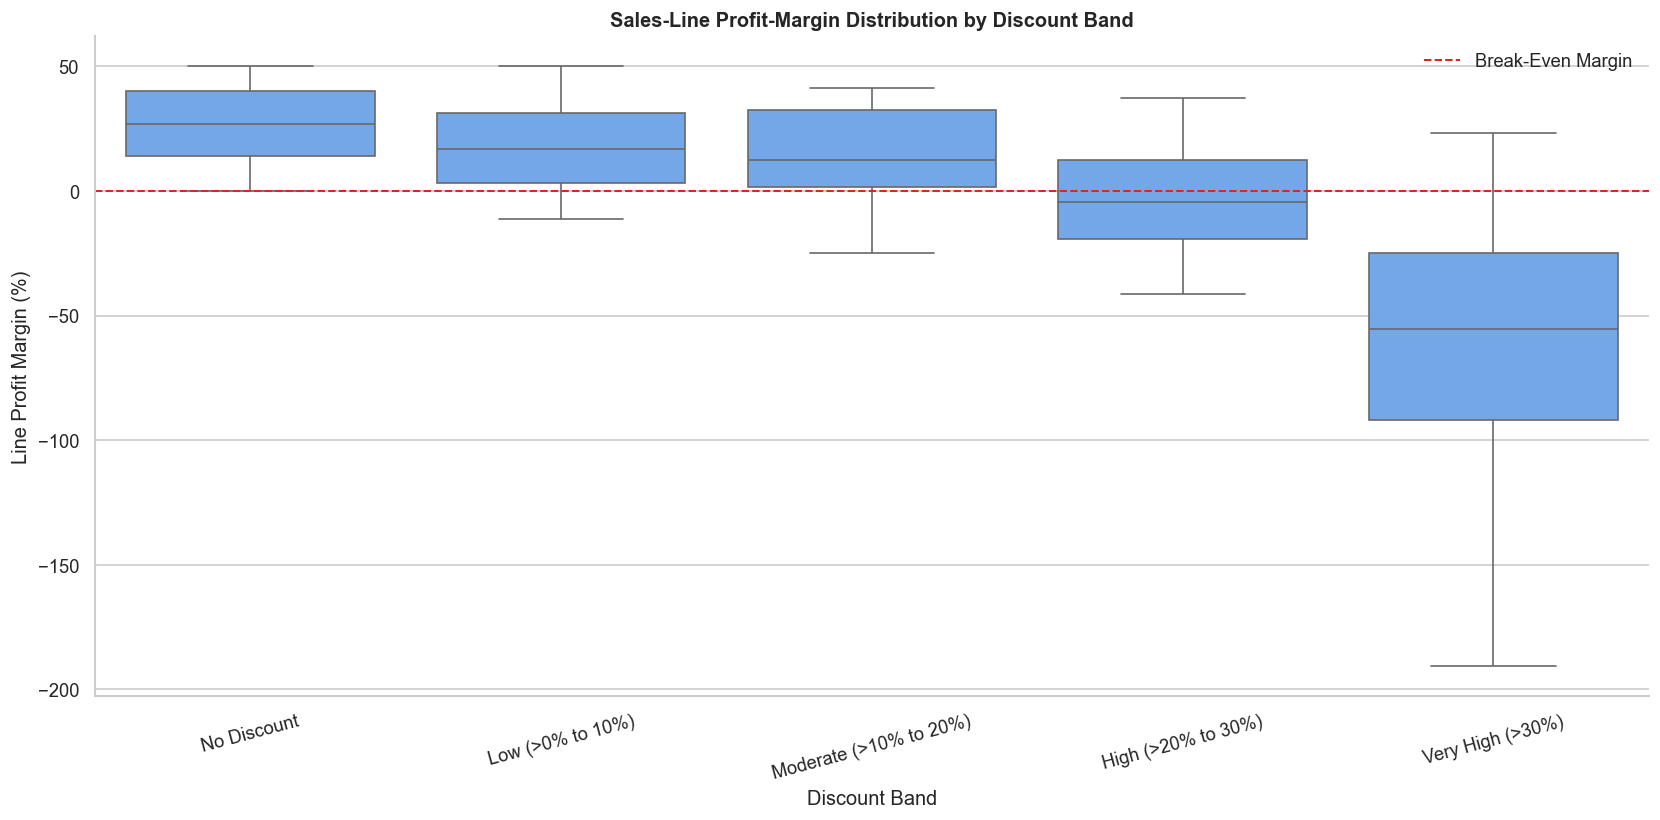

In [7]:
discount_boxplot_data = statistical_data.copy()

discount_boxplot_data["line_margin_percent"] = (
    discount_boxplot_data["line_profit_margin"]
    * 100
)


fig, axis = plt.subplots(figsize=(14, 7))

sns.boxplot(
    data=discount_boxplot_data,
    x="discount_band",
    y="line_margin_percent",
    order=discount_labels,
    showfliers=False,
    color="#60A5FA",
    ax=axis
)

axis.axhline(
    0,
    color="#DC2626",
    linestyle="--",
    linewidth=1.2,
    label="Break-Even Margin"
)

axis.set_title(
    "Sales-Line Profit-Margin Distribution by Discount Band"
)
axis.set_xlabel("Discount Band")
axis.set_ylabel("Line Profit Margin (%)")
axis.tick_params(
    axis="x",
    rotation=15
)

axis.legend(
    frameon=False
)

sns.despine()
plt.tight_layout()
plt.show()

### Discount Statistical Findings

- Spearman correlation identified a **strong negative association** between discount and line profit margin: **ρ = -0.6691**.
- The association was statistically significant, with a p-value below the reporting precision.
- Discount band and loss status were strongly associated: **Cramér's V = 0.8393**, representing a large practical effect.
- The loss-line rate increased from **0.00% without discount** to **92.44% above 30% discount**.
- Profit-margin distributions differed significantly across discount bands.
- The Kruskal–Wallis effect size was large: **ε² = 0.5020**.
- Median line margin declined from **27.00% without discount** to **-4.29% at 20%–30% discount** and **-55.52% above 30% discount**.

**Business conclusion:** The statistical evidence supports stronger approval and profitability controls for discounts above 20%, with the highest priority placed on discounts above 30%.

**Limitations:** These tests establish association rather than causation. Product mix, geography, and cost structure may influence both discounts and profit. Sales lines within the same order may also be related, so practical effect sizes are emphasized alongside p-values.

## 5. Product-Category Profitability Test

### 5.1 Product-Level Margin Differences

**Null hypothesis (H₀):** Product-level profit-margin distributions are the same across Furniture, Office Supplies, and Technology.

**Alternative hypothesis (H₁):** At least one category has a different product-level profit-margin distribution.

I aggregate transactions to one record per validated product before applying the Kruskal–Wallis test.

In [8]:
product_statistical_data = (
    orders
    .groupby(
        [
            "product_id",
            "product_name",
            "category"
        ],
        as_index=False
    )
    .agg(
        revenue=("sales", "sum"),
        profit=("profit", "sum"),
        orders=("order_key", "nunique"),
        sales_lines=("row_id", "count")
    )
)

product_statistical_data["product_profit_margin"] = (
    product_statistical_data["profit"]
    / product_statistical_data["revenue"]
)


category_margin_groups = [
    group["product_profit_margin"].to_numpy()
    for _, group in product_statistical_data.groupby(
        "category"
    )
]


category_kruskal_statistic, category_kruskal_p_value = (
    stats.kruskal(
        *category_margin_groups
    )
)


category_count = (
    product_statistical_data["category"].nunique()
)

product_count = len(product_statistical_data)

category_epsilon_squared = (
    category_kruskal_statistic
    - category_count
    + 1
) / (
    product_count
    - category_count
)

category_epsilon_squared = max(
    0,
    min(1, category_epsilon_squared)
)


if category_epsilon_squared < 0.01:
    category_effect_strength = "Negligible"
elif category_epsilon_squared < 0.06:
    category_effect_strength = "Small"
elif category_epsilon_squared < 0.14:
    category_effect_strength = "Moderate"
else:
    category_effect_strength = "Large"


category_product_summary = (
    product_statistical_data
    .groupby(
        "category",
        as_index=False
    )
    .agg(
        products=("product_id", "nunique"),
        median_product_margin=(
            "product_profit_margin",
            "median"
        ),
        lower_quartile=(
            "product_profit_margin",
            lambda values: values.quantile(0.25)
        ),
        upper_quartile=(
            "product_profit_margin",
            lambda values: values.quantile(0.75)
        )
    )
)


category_product_display = category_product_summary.copy()

for column in [
    "median_product_margin",
    "lower_quartile",
    "upper_quartile"
]:
    category_product_display[column] = (
        category_product_display[column]
        .map("{:.2%}".format)
    )

category_product_display = category_product_display.rename(
    columns={
        "category": "Category",
        "products": "Products",
        "median_product_margin": "Median Product Margin",
        "lower_quartile": "25th Percentile",
        "upper_quartile": "75th Percentile"
    }
)

display(category_product_display)


category_test_result = pd.DataFrame({
    "Metric": [
        "Kruskal-Wallis Statistic",
        "Degrees of Freedom",
        "P-Value",
        "Epsilon-Squared",
        "Effect Strength",
        "Decision"
    ],
    "Result": [
        f"{category_kruskal_statistic:,.4f}",
        f"{category_count - 1}",
        f"{category_kruskal_p_value:.4e}",
        f"{category_epsilon_squared:.4f}",
        category_effect_strength,
        (
            "Reject H0"
            if category_kruskal_p_value
            < SIGNIFICANCE_LEVEL
            else "Fail to reject H0"
        )
    ]
})

display(category_test_result)

,Category,Products,Median Product Margin,25th Percentile,75th Percentile
0,Furniture,841,9.04%,-4.14%,20.50%
1,Office Supplies,2071,20.75%,8.36%,33.01%
2,Technology,876,13.84%,5.01%,24.29%


,Metric,Result
0,Kruskal-Wallis Statistic,279.7603
1,Degrees of Freedom,2
2,P-Value,1.7816e-61
3,Epsilon-Squared,0.0734
4,Effect Strength,Moderate
5,Decision,Reject H0


### 5.2 Pairwise Category Comparisons

I perform pairwise Mann–Whitney tests after the significant Kruskal–Wallis result. Holm correction controls the family-wise error rate across the three comparisons.

Rank-biserial correlation measures the direction and practical strength of each pairwise difference.

In [9]:
category_names = sorted(
    product_statistical_data["category"].unique()
)

category_pairs = list(
    combinations(category_names, 2)
)

pairwise_category_results = []


for first_category, second_category in category_pairs:
    first_values = product_statistical_data.loc[
        product_statistical_data["category"]
        .eq(first_category),
        "product_profit_margin"
    ].to_numpy()

    second_values = product_statistical_data.loc[
        product_statistical_data["category"]
        .eq(second_category),
        "product_profit_margin"
    ].to_numpy()

    mann_whitney_statistic, raw_p_value = (
        stats.mannwhitneyu(
            first_values,
            second_values,
            alternative="two-sided"
        )
    )

    rank_biserial = (
        2 * mann_whitney_statistic
        / (
            len(first_values)
            * len(second_values)
        )
        - 1
    )

    pairwise_category_results.append({
        "Comparison": (
            f"{first_category} vs {second_category}"
        ),
        "First Category Median": np.median(first_values),
        "Second Category Median": np.median(second_values),
        "Mann-Whitney U": mann_whitney_statistic,
        "Raw P-Value": raw_p_value,
        "Rank-Biserial Correlation": rank_biserial
    })


pairwise_category_results = pd.DataFrame(
    pairwise_category_results
).sort_values(
    "Raw P-Value"
).reset_index(drop=True)


number_of_comparisons = len(
    pairwise_category_results
)

holm_multipliers = (
    number_of_comparisons
    - np.arange(number_of_comparisons)
)

holm_adjusted_values = (
    pairwise_category_results["Raw P-Value"]
    * holm_multipliers
)

pairwise_category_results["Holm Adjusted P-Value"] = (
    np.maximum.accumulate(
        holm_adjusted_values
    )
    .clip(upper=1)
)


absolute_rank_biserial = (
    pairwise_category_results[
        "Rank-Biserial Correlation"
    ].abs()
)

pairwise_category_results["Effect Strength"] = np.select(
    [
        absolute_rank_biserial < 0.10,
        absolute_rank_biserial < 0.30,
        absolute_rank_biserial < 0.50
    ],
    [
        "Negligible",
        "Small",
        "Moderate"
    ],
    default="Large"
)

pairwise_category_results["Decision"] = np.where(
    pairwise_category_results[
        "Holm Adjusted P-Value"
    ] < SIGNIFICANCE_LEVEL,
    "Reject H0",
    "Fail to reject H0"
)


pairwise_category_display = (
    pairwise_category_results.copy()
)

pairwise_category_display["First Category Median"] = (
    pairwise_category_display["First Category Median"]
    .map("{:.2%}".format)
)

pairwise_category_display["Second Category Median"] = (
    pairwise_category_display["Second Category Median"]
    .map("{:.2%}".format)
)

pairwise_category_display["Mann-Whitney U"] = (
    pairwise_category_display["Mann-Whitney U"]
    .map("{:,.1f}".format)
)

pairwise_category_display["Raw P-Value"] = (
    pairwise_category_display["Raw P-Value"]
    .map("{:.4e}".format)
)

pairwise_category_display["Holm Adjusted P-Value"] = (
    pairwise_category_display[
        "Holm Adjusted P-Value"
    ]
    .map("{:.4e}".format)
)

pairwise_category_display[
    "Rank-Biserial Correlation"
] = (
    pairwise_category_display[
        "Rank-Biserial Correlation"
    ]
    .map("{:.4f}".format)
)

display(pairwise_category_display)

,Comparison,First Category Median,Second Category Median,Mann-Whitney U,Raw P-Value,Rank-Biserial Correlation,Holm Adjusted P-Value,Effect Strength,Decision
0,Furniture vs Office Supplies,9.04%,20.75%,"545,586.5",2.3074e-56,-0.3735,6.9223e-56,Moderate,Reject H0
1,Office Supplies vs Technology,20.75%,13.84%,"1,100,874.0",4.3612e-20,0.2136,8.7223e-20,Small,Reject H0
2,Furniture vs Technology,9.04%,13.84%,"296,455.0",2.5376e-12,-0.1952,2.5376e-12,Small,Reject H0


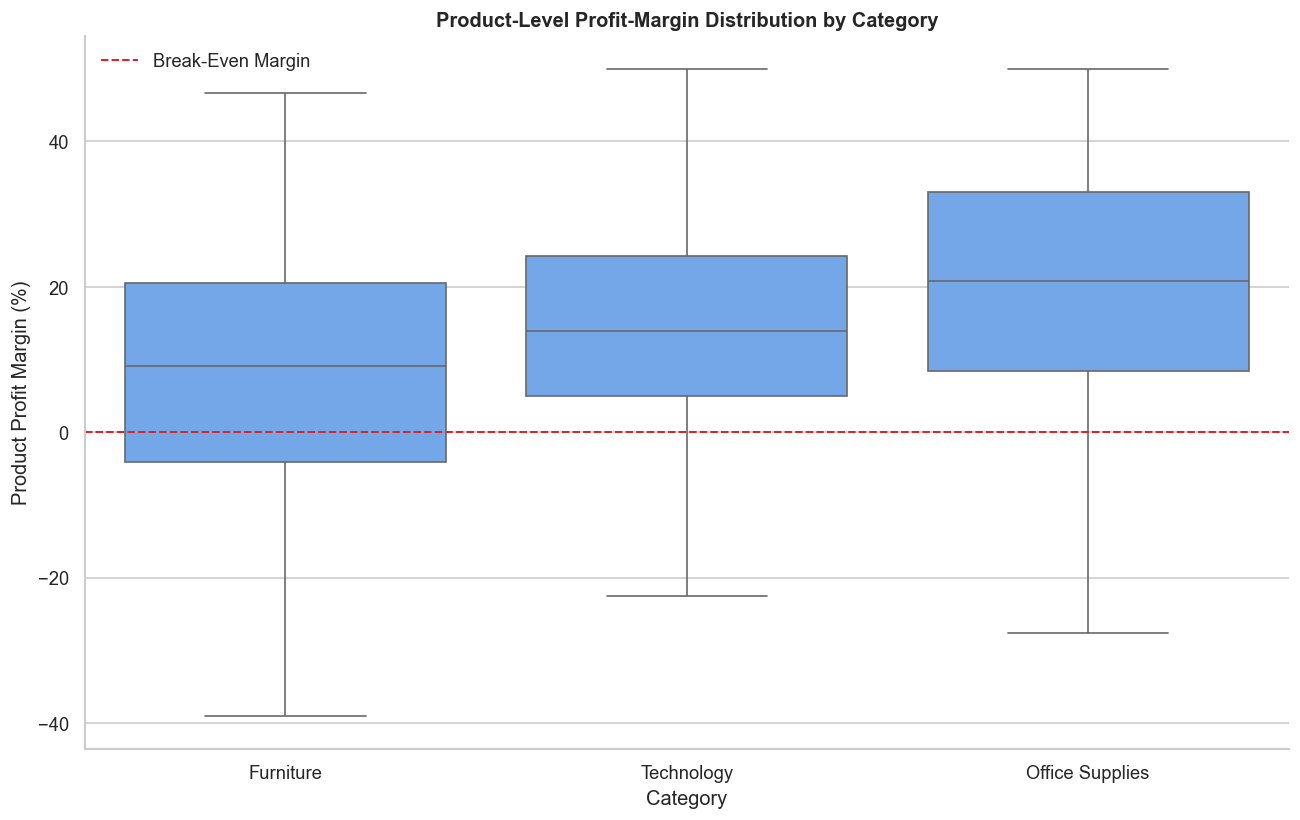

In [10]:
category_boxplot_data = product_statistical_data.copy()

category_boxplot_data["product_margin_percent"] = (
    category_boxplot_data["product_profit_margin"]
    * 100
)

category_order = [
    "Furniture",
    "Technology",
    "Office Supplies"
]


fig, axis = plt.subplots(figsize=(11, 7))

sns.boxplot(
    data=category_boxplot_data,
    x="category",
    y="product_margin_percent",
    order=category_order,
    showfliers=False,
    color="#60A5FA",
    ax=axis
)

axis.axhline(
    0,
    color="#DC2626",
    linestyle="--",
    linewidth=1.2,
    label="Break-Even Margin"
)

axis.set_title(
    "Product-Level Profit-Margin Distribution by Category"
)
axis.set_xlabel("Category")
axis.set_ylabel("Product Profit Margin (%)")

axis.legend(
    frameon=False
)

sns.despine()
plt.tight_layout()
plt.show()

### Category Statistical Findings

- Product-level profit-margin distributions differed significantly across the three categories.
- The overall category effect was **moderate**, with **ε² = 0.0734**.
- Furniture recorded the lowest median product margin at **9.04%**, compared with **13.84% for Technology** and **20.75% for Office Supplies**.
- Furniture's 25th-percentile product margin was **-4.14%**, indicating broader product-level profitability pressure.
- Furniture versus Office Supplies showed the largest pairwise difference, with a **moderate rank-biserial effect of -0.3735**.
- Furniture versus Technology and Office Supplies versus Technology were statistically significant but had smaller practical effects.
- All pairwise results remained significant after Holm multiple-comparison correction.

**Business conclusion:** Furniture's weaker profitability is not limited to the aggregate Tables result. The product-level distribution also underperforms the other categories, supporting a broader Furniture pricing, discount, and product-portfolio review.

**Limitation:** Every product receives equal weight in this statistical test regardless of revenue size. Aggregate financial impact should therefore be interpreted together with the revenue-weighted EDA results.

## 6. Cohort Retention Analysis

### 6.1 Monthly Customer Cohorts

I assign each customer to the month of their first observed order and measure the percentage of the original cohort that placed an order in each subsequent cohort month.

Cohort Month 1 represents the acquisition month. Retention is based on customer activity, not revenue.

Because the dataset begins in 2012, acquisition means first observed acquisition within the available data window.

In [11]:
customer_month_activity = orders[
    [
        "customer_key",
        "order_date"
    ]
].copy()

customer_month_activity["order_month"] = (
    customer_month_activity["order_date"]
    .dt.to_period("M")
)

customer_month_activity = (
    customer_month_activity[
        [
            "customer_key",
            "order_month"
        ]
    ]
    .drop_duplicates()
)


customer_first_month = (
    customer_month_activity
    .groupby(
        "customer_key",
        as_index=False
    )
    .agg(
        cohort_month=("order_month", "min")
    )
)


customer_month_activity = (
    customer_month_activity
    .merge(
        customer_first_month,
        on="customer_key",
        how="left",
        validate="many_to_one"
    )
)


customer_month_activity["cohort_index"] = (
    (
        customer_month_activity["order_month"].dt.year
        - customer_month_activity["cohort_month"].dt.year
    )
    * 12
    + (
        customer_month_activity["order_month"].dt.month
        - customer_month_activity["cohort_month"].dt.month
    )
    + 1
)


observed_cohort_activity = (
    customer_month_activity
    .groupby(
        [
            "cohort_month",
            "cohort_index"
        ],
        as_index=False
    )
    .agg(
        active_customers=("customer_key", "nunique")
    )
)


cohort_sizes = (
    customer_first_month
    .groupby(
        "cohort_month",
        as_index=False
    )
    .agg(
        cohort_size=("customer_key", "nunique")
    )
)


latest_observed_month = (
    orders["order_date"].max().to_period("M")
)

cohort_month_grid = []


for cohort_month in cohort_sizes["cohort_month"]:
    maximum_observable_index = (
        (
            latest_observed_month.year
            - cohort_month.year
        )
        * 12
        + (
            latest_observed_month.month
            - cohort_month.month
        )
        + 1
    )

    cohort_month_grid.append(
        pd.DataFrame({
            "cohort_month": cohort_month,
            "cohort_index": range(
                1,
                maximum_observable_index + 1
            )
        })
    )


complete_cohort_grid = pd.concat(
    cohort_month_grid,
    ignore_index=True
)


cohort_activity = complete_cohort_grid.merge(
    observed_cohort_activity,
    on=[
        "cohort_month",
        "cohort_index"
    ],
    how="left",
    validate="one_to_one"
)

cohort_activity["active_customers"] = (
    cohort_activity["active_customers"]
    .fillna(0)
    .astype(int)
)


cohort_activity = cohort_activity.merge(
    cohort_sizes,
    on="cohort_month",
    how="left",
    validate="many_to_one"
)

cohort_activity["retention_rate"] = (
    cohort_activity["active_customers"]
    / cohort_activity["cohort_size"]
)


retention_matrix = (
    cohort_activity
    .pivot(
        index="cohort_month",
        columns="cohort_index",
        values="retention_rate"
    )
    .sort_index()
)

retention_12_months = retention_matrix.reindex(
    columns=range(1, 13)
)


if cohort_sizes["cohort_size"].sum() != orders[
    "customer_key"
].nunique():
    raise ValueError(
        "Cohort sizes do not reconcile with the customer count."
    )

if not cohort_activity["retention_rate"].between(
    0,
    1
).all():
    raise ValueError(
        "Invalid cohort retention rate detected."
    )


cohort_size_display = cohort_sizes.copy()

cohort_size_display["cohort_month"] = (
    cohort_size_display["cohort_month"].astype(str)
)

cohort_size_display = cohort_size_display.rename(
    columns={
        "cohort_month": "Cohort Month",
        "cohort_size": "Customers"
    }
)

display(cohort_size_display)


retention_display = retention_12_months.copy()

retention_display.index = (
    retention_display.index.astype(str)
)

retention_display = retention_display.map(
    lambda value:
    ""
    if pd.isna(value)
    else f"{value:.1%}"
)

display(retention_display)

,Cohort Month,Customers
0,2012-01,195
1,2012-02,135
2,2012-03,140
3,2012-04,92
4,2012-05,57
5,2012-06,80
6,2012-07,28
7,2012-08,27
8,2012-09,23
9,2012-10,14


cohort_index,1,2,3,4,5,6,7,8,9,10,11,12
cohort_month,,,,,,,,,,,,
2012-01,100.0%,21.5%,29.2%,27.7%,37.4%,39.5%,31.3%,46.7%,49.7%,39.5%,54.4%,57.4%
2012-02,100.0%,20.0%,26.7%,37.8%,43.0%,27.4%,35.6%,40.7%,37.8%,50.4%,48.1%,24.4%
2012-03,100.0%,29.3%,31.4%,38.6%,25.0%,30.7%,43.6%,39.3%,52.1%,46.4%,27.9%,19.3%
2012-04,100.0%,29.3%,43.5%,31.5%,40.2%,48.9%,43.5%,43.5%,53.3%,26.1%,22.8%,48.9%
2012-05,100.0%,40.4%,28.1%,42.1%,50.9%,50.9%,52.6%,45.6%,22.8%,26.3%,38.6%,33.3%
2012-06,100.0%,23.8%,46.2%,48.8%,41.2%,56.2%,48.8%,27.5%,35.0%,42.5%,32.5%,35.0%
2012-07,100.0%,64.3%,46.4%,39.3%,50.0%,50.0%,39.3%,10.7%,17.9%,32.1%,39.3%,46.4%
2012-08,100.0%,48.1%,44.4%,40.7%,63.0%,40.7%,25.9%,18.5%,37.0%,33.3%,37.0%,29.6%
2012-09,100.0%,39.1%,56.5%,60.9%,17.4%,17.4%,21.7%,34.8%,34.8%,69.6%,52.2%,56.5%


### 6.2 Twelve-Month Retention Heatmap

I visualize cohorts with at least 20 customers to reduce misleading volatility from very small cohort sizes. Smaller cohorts remain available in the detailed table but are excluded from the comparative heatmap.

Eligible cohorts: 9
Customers represented: 777
Customer coverage: 97.61%


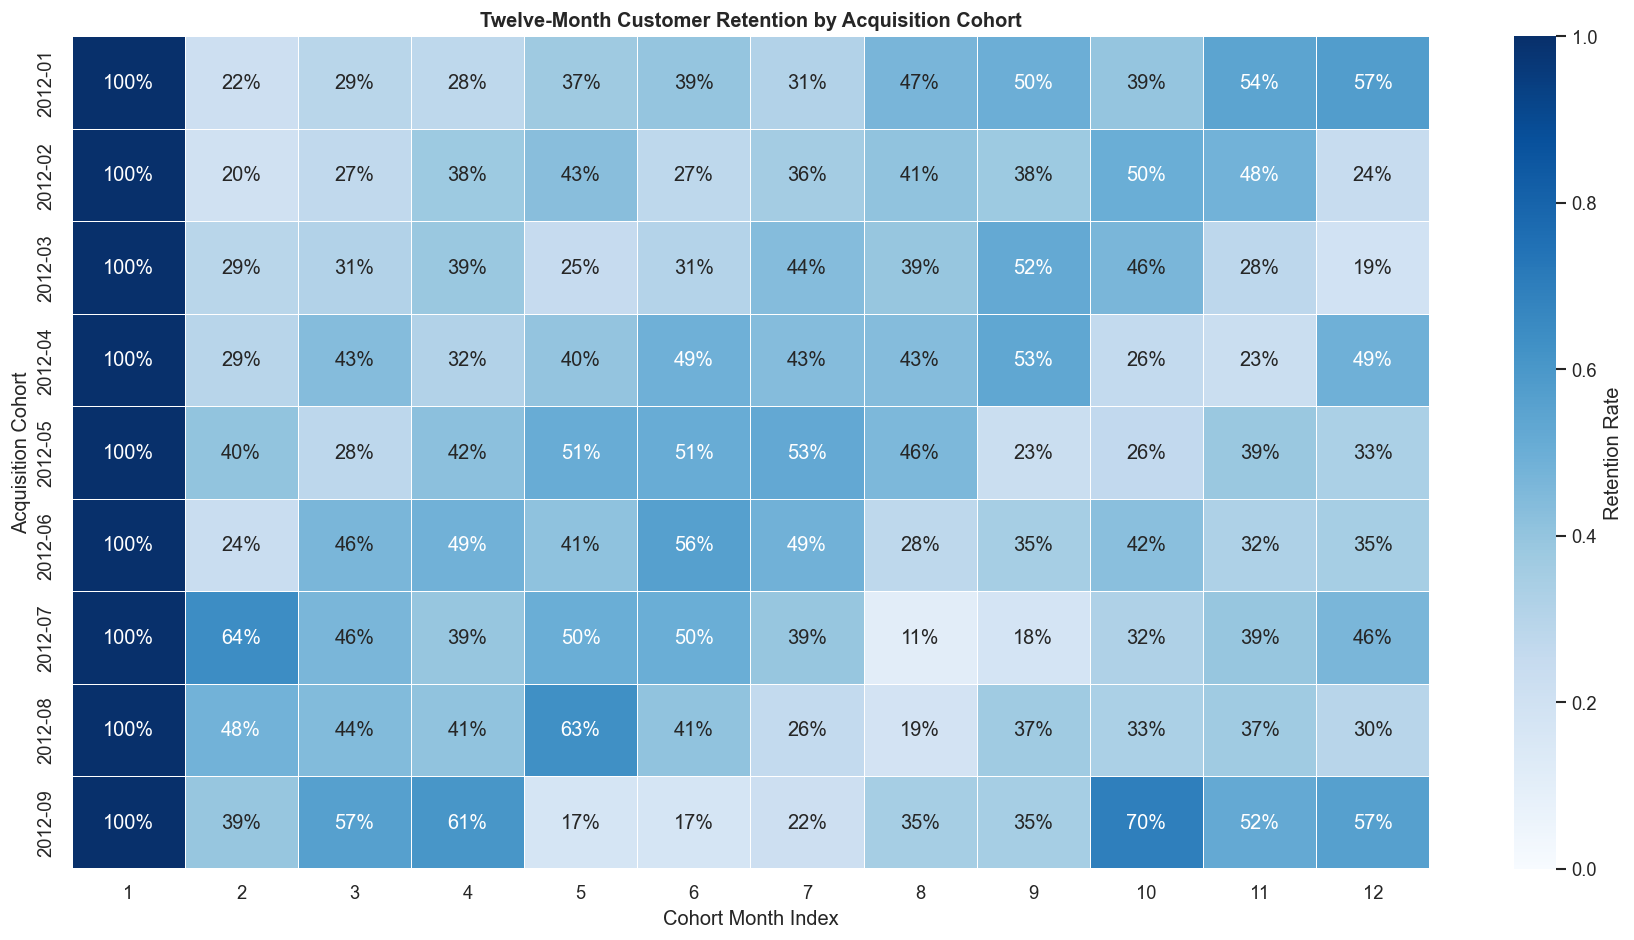

In [12]:
MINIMUM_COHORT_SIZE = 20


eligible_cohort_months = cohort_sizes.loc[
    cohort_sizes["cohort_size"].ge(
        MINIMUM_COHORT_SIZE
    ),
    "cohort_month"
]


eligible_retention_12_months = (
    retention_12_months
    .loc[eligible_cohort_months]
    .copy()
)

eligible_retention_12_months.index = (
    eligible_retention_12_months.index.astype(str)
)


eligible_customer_count = (
    cohort_sizes.loc[
        cohort_sizes["cohort_size"].ge(
            MINIMUM_COHORT_SIZE
        ),
        "cohort_size"
    ]
    .sum()
)

eligible_customer_share = (
    eligible_customer_count
    / cohort_sizes["cohort_size"].sum()
)


print(
    "Eligible cohorts:",
    len(eligible_cohort_months)
)

print(
    "Customers represented:",
    f"{eligible_customer_count:,}"
)

print(
    "Customer coverage:",
    f"{eligible_customer_share:.2%}"
)


fig, axis = plt.subplots(figsize=(15, 8))

sns.heatmap(
    eligible_retention_12_months,
    annot=True,
    fmt=".0%",
    cmap="Blues",
    vmin=0,
    vmax=1,
    linewidths=0.5,
    cbar_kws={
        "label": "Retention Rate"
    },
    ax=axis
)

axis.set_title(
    "Twelve-Month Customer Retention by Acquisition Cohort"
)
axis.set_xlabel("Cohort Month Index")
axis.set_ylabel("Acquisition Cohort")

plt.tight_layout()
plt.show()

In [13]:
eligible_cohort_activity = cohort_activity.loc[
    cohort_activity["cohort_month"].isin(
        eligible_cohort_months
    )
    & cohort_activity["cohort_index"].between(
        1,
        12
    )
].copy()


weighted_retention = (
    eligible_cohort_activity
    .groupby(
        "cohort_index",
        as_index=False
    )
    .agg(
        active_customers=("active_customers", "sum"),
        eligible_customers=("cohort_size", "sum")
    )
)

weighted_retention["weighted_retention_rate"] = (
    weighted_retention["active_customers"]
    / weighted_retention["eligible_customers"]
)


weighted_retention_display = weighted_retention.copy()

weighted_retention_display[
    "weighted_retention_rate"
] = (
    weighted_retention_display[
        "weighted_retention_rate"
    ]
    .map("{:.2%}".format)
)

weighted_retention_display = (
    weighted_retention_display.rename(
        columns={
            "cohort_index": "Cohort Month",
            "active_customers": "Active Customers",
            "eligible_customers": "Eligible Customers",
            "weighted_retention_rate": (
                "Weighted Retention Rate"
            )
        }
    )
)

display(weighted_retention_display)

,Cohort Month,Active Customers,Eligible Customers,Weighted Retention Rate
0,1,777,777,100.00%
1,2,219,777,28.19%
2,3,268,777,34.49%
3,4,287,777,36.94%
4,5,300,777,38.61%
5,6,305,777,39.25%
6,7,302,777,38.87%
7,8,305,777,39.25%
8,9,334,777,42.99%
9,10,317,777,40.80%


### Cohort Retention Findings

- Nine cohorts with at least 20 customers represented **777 customers**, or **97.61% of the customer base**.
- Weighted monthly retention fell to **28.19% in Cohort Month 2**.
- Activity recovered to **34.49%–39.25% between Cohort Months 3 and 8**.
- The highest post-acquisition weighted retention occurred in **Cohort Month 9 at 42.99%**.
- Weighted retention was **38.35% in Cohort Month 12**.
- The non-monotonic pattern indicates that customers can skip purchasing months and return later.

**Business implication:** The sharp Month-2 decline suggests an opportunity to test early post-purchase engagement. Later recovery indicates that reactivation and seasonal purchasing are important parts of customer behaviour.

**Limitations:** This is monthly activity retention, not continuous survival retention. Nearly all customers were first observed during 2012, while later cohorts were extremely small. The dataset therefore supports behavioural retention analysis better than customer-acquisition trend analysis.

## 7. Product Combination Analysis

### 7.1 Order Baskets and Product Pairs

I create one basket per analytical order using unique Product IDs. Product pairs are counted once per order, regardless of duplicate sales lines.

The validated analytical `order_key` is used instead of the raw Order ID to avoid the known Order ID collisions.

In [14]:
order_baskets = (
    orders
    .groupby(
        "order_key"
    )["product_id"]
    .agg(
        lambda product_ids:
        tuple(sorted(set(product_ids)))
    )
    .reset_index(
        name="product_ids"
    )
)

order_baskets["unique_products"] = (
    order_baskets["product_ids"].str.len()
)


pair_records = [
    {
        "product_a": product_a,
        "product_b": product_b
    }
    for product_ids in order_baskets["product_ids"]
    for product_a, product_b in combinations(
        product_ids,
        2
    )
]


product_pair_counts = (
    pd.DataFrame(pair_records)
    .value_counts(
        [
            "product_a",
            "product_b"
        ]
    )
    .reset_index(
        name="pair_order_count"
    )
)


basket_summary = pd.DataFrame({
    "Metric": [
        "Analytical Orders",
        "Single-Product Orders",
        "Multi-Product Orders",
        "Multi-Product Order Rate",
        "Average Unique Products per Order",
        "Maximum Unique Products in One Order",
        "Unique Product Pairs Observed"
    ],
    "Value": [
        f"{len(order_baskets):,}",
        (
            f"{order_baskets['unique_products']
            .eq(1).sum():,}"
        ),
        (
            f"{order_baskets['unique_products']
            .gt(1).sum():,}"
        ),
        (
            f"{order_baskets['unique_products']
            .gt(1).mean():.2%}"
        ),
        f"{order_baskets['unique_products'].mean():.2f}",
        f"{order_baskets['unique_products'].max():,}",
        f"{len(product_pair_counts):,}"
    ]
})

display(basket_summary)

,Metric,Value
0,Analytical Orders,"25,739"
1,Single-Product Orders,"12,957"
2,Multi-Product Orders,"12,782"
3,Multi-Product Order Rate,49.66%
4,Average Unique Products per Order,1.99
5,Maximum Unique Products in One Order,14
6,Unique Product Pairs Observed,"49,848"


### 7.2 Pair Frequency and Basket Metrics

I calculate order-level support, directional confidence, and lift for every observed product pair. I first examine pair-frequency sparsity before selecting a minimum evidence threshold.

In [15]:
product_order_counts = (
    orders
    .groupby(
        "product_id",
        as_index=False
    )
    .agg(
        product_order_count=("order_key", "nunique")
    )
)


product_lookup = (
    orders[
        [
            "product_id",
            "product_name"
        ]
    ]
    .drop_duplicates()
    .set_index("product_id")["product_name"]
)


product_pair_metrics = (
    product_pair_counts
    .merge(
        product_order_counts.rename(
            columns={
                "product_id": "product_a",
                "product_order_count": "product_a_orders"
            }
        ),
        on="product_a",
        how="left",
        validate="many_to_one"
    )
    .merge(
        product_order_counts.rename(
            columns={
                "product_id": "product_b",
                "product_order_count": "product_b_orders"
            }
        ),
        on="product_b",
        how="left",
        validate="many_to_one"
    )
)


total_basket_orders = len(order_baskets)

product_pair_metrics["support"] = (
    product_pair_metrics["pair_order_count"]
    / total_basket_orders
)

product_pair_metrics["confidence_a_to_b"] = (
    product_pair_metrics["pair_order_count"]
    / product_pair_metrics["product_a_orders"]
)

product_pair_metrics["confidence_b_to_a"] = (
    product_pair_metrics["pair_order_count"]
    / product_pair_metrics["product_b_orders"]
)

product_pair_metrics["lift"] = (
    product_pair_metrics["support"]
    / (
        (
            product_pair_metrics["product_a_orders"]
            / total_basket_orders
        )
        * (
            product_pair_metrics["product_b_orders"]
            / total_basket_orders
        )
    )
)


product_pair_metrics["product_a_name"] = (
    product_pair_metrics["product_a"]
    .map(product_lookup)
)

product_pair_metrics["product_b_name"] = (
    product_pair_metrics["product_b"]
    .map(product_lookup)
)


if product_pair_metrics[
    [
        "product_a_name",
        "product_b_name",
        "lift"
    ]
].isna().any().any():
    raise ValueError(
        "Product-pair metrics contain missing values."
    )


pair_frequency_summary = pd.DataFrame({
    "Metric": [
        "Maximum Pair Order Count",
        "Pairs Appearing at Least Twice",
        "Pairs Appearing in at Least 3 Orders",
        "Pairs Appearing in at Least 5 Orders",
        "Pairs Appearing in at Least 10 Orders"
    ],
    "Value": [
        f"{product_pair_metrics['pair_order_count'].max():,}",
        (
            f"{product_pair_metrics['pair_order_count']
            .ge(2).sum():,}"
        ),
        (
            f"{product_pair_metrics['pair_order_count']
            .ge(3).sum():,}"
        ),
        (
            f"{product_pair_metrics['pair_order_count']
            .ge(5).sum():,}"
        ),
        (
            f"{product_pair_metrics['pair_order_count']
            .ge(10).sum():,}"
        )
    ]
})

display(pair_frequency_summary)


top_pair_counts = (
    product_pair_metrics
    .nlargest(
        10,
        "pair_order_count"
    )
    [
        [
            "product_a_name",
            "product_b_name",
            "pair_order_count",
            "support",
            "lift"
        ]
    ]
    .copy()
)

top_pair_counts["support"] = (
    top_pair_counts["support"]
    .map("{:.4%}".format)
)

top_pair_counts["lift"] = (
    top_pair_counts["lift"]
    .map("{:.2f}".format)
)

top_pair_counts = top_pair_counts.rename(
    columns={
        "product_a_name": "Product A",
        "product_b_name": "Product B",
        "pair_order_count": "Pair Orders",
        "support": "Support",
        "lift": "Lift"
    }
)

display(top_pair_counts)

,Metric,Value
0,Maximum Pair Order Count,3
1,Pairs Appearing at Least Twice,984
2,Pairs Appearing in at Least 3 Orders,30
3,Pairs Appearing in at Least 5 Orders,0
4,Pairs Appearing in at Least 10 Orders,0


,Product A,Product B,Pair Orders,Support,Lift
0,KI Adjustable-Height Table,Staples,3,0.0117%,19.32
1,Newell 34,Staples,3,0.0117%,49.69
2,"#10 White Business Envelopes,4 1/8 x 9 1/2",Staples,3,0.0117%,49.69
3,Satellite Sectional Post Binders,Staples,3,0.0117%,31.62
4,Hon Olson Stacker Chairs,Staples,3,0.0117%,86.96
5,Hoover Shoulder Vac Commercial Portable Vacuum,Staples,3,0.0117%,57.97
6,Staples,Xerox 1916,3,0.0117%,49.69
7,Staples,Adjustable Depth Letter/Legal Cart,3,0.0117%,31.62
8,"Sanford Pencil Sharpener, Easy-Erase","Avery 3-Hole Punch, Recycled",3,0.0117%,32.16
9,"Smead Shelving, Blue","Logitech Numeric Keypad, Bluetooth",3,0.0117%,113.55


### Product-Level Pair Finding and Analytical Decision

- The dataset contained **49,848 observed product pairs**, but the maximum pair frequency was only **three orders**.
- Only **984 pairs** appeared more than once, and only **30 pairs** appeared in three orders.
- No exact product pair appeared in five or more analytical orders.
- The highest-frequency pairs had support of only **0.0117%**.
- Several pairs showed high lift because the individual products were rare, not because the pair had strong transaction volume.

**Analytical decision:** Exact product-level combinations are too sparse for reliable bundling recommendations. I report the observed pairs transparently but do not treat them as stable customer preferences. I continue the analysis at the sub-category level, where repeated co-purchase patterns can be evaluated with stronger evidence.

### 7.3 Sub-Category Market Basket Analysis

I aggregate products to their business sub-categories and calculate support, directional confidence, and lift for each sub-category pair.

In [16]:
sub_category_baskets = (
    orders
    .groupby(
        "order_key"
    )["sub_category"]
    .agg(
        lambda sub_categories:
        tuple(sorted(set(sub_categories)))
    )
    .reset_index(
        name="sub_categories"
    )
)

sub_category_baskets[
    "unique_sub_categories"
] = (
    sub_category_baskets[
        "sub_categories"
    ].str.len()
)


sub_category_pair_records = [
    {
        "sub_category_a": sub_category_a,
        "sub_category_b": sub_category_b
    }
    for sub_categories in sub_category_baskets[
        "sub_categories"
    ]
    for sub_category_a, sub_category_b in combinations(
        sub_categories,
        2
    )
]


sub_category_pair_counts = (
    pd.DataFrame(
        sub_category_pair_records
    )
    .value_counts(
        [
            "sub_category_a",
            "sub_category_b"
        ]
    )
    .reset_index(
        name="pair_order_count"
    )
)


sub_category_order_counts = (
    orders
    .groupby(
        "sub_category",
        as_index=False
    )
    .agg(
        sub_category_order_count=(
            "order_key",
            "nunique"
        )
    )
)


sub_category_pair_metrics = (
    sub_category_pair_counts
    .merge(
        sub_category_order_counts.rename(
            columns={
                "sub_category": "sub_category_a",
                "sub_category_order_count": (
                    "sub_category_a_orders"
                )
            }
        ),
        on="sub_category_a",
        how="left",
        validate="many_to_one"
    )
    .merge(
        sub_category_order_counts.rename(
            columns={
                "sub_category": "sub_category_b",
                "sub_category_order_count": (
                    "sub_category_b_orders"
                )
            }
        ),
        on="sub_category_b",
        how="left",
        validate="many_to_one"
    )
)


sub_category_pair_metrics["support"] = (
    sub_category_pair_metrics["pair_order_count"]
    / total_basket_orders
)

sub_category_pair_metrics["confidence_a_to_b"] = (
    sub_category_pair_metrics["pair_order_count"]
    / sub_category_pair_metrics[
        "sub_category_a_orders"
    ]
)

sub_category_pair_metrics["confidence_b_to_a"] = (
    sub_category_pair_metrics["pair_order_count"]
    / sub_category_pair_metrics[
        "sub_category_b_orders"
    ]
)

sub_category_pair_metrics["lift"] = (
    sub_category_pair_metrics["support"]
    / (
        (
            sub_category_pair_metrics[
                "sub_category_a_orders"
            ]
            / total_basket_orders
        )
        * (
            sub_category_pair_metrics[
                "sub_category_b_orders"
            ]
            / total_basket_orders
        )
    )
)


sub_category_basket_summary = pd.DataFrame({
    "Metric": [
        "Orders with Multiple Sub-Categories",
        "Multi-Sub-Category Order Rate",
        "Unique Sub-Category Pairs",
        "Maximum Pair Order Count",
        "Minimum Pair Order Count"
    ],
    "Value": [
        (
            f"{sub_category_baskets[
                'unique_sub_categories'
            ].gt(1).sum():,}"
        ),
        (
            f"{sub_category_baskets[
                'unique_sub_categories'
            ].gt(1).mean():.2%}"
        ),
        f"{len(sub_category_pair_metrics):,}",
        (
            f"{sub_category_pair_metrics[
                'pair_order_count'
            ].max():,}"
        ),
        (
            f"{sub_category_pair_metrics[
                'pair_order_count'
            ].min():,}"
        )
    ]
})

display(sub_category_basket_summary)


top_sub_category_pairs = (
    sub_category_pair_metrics
    .nlargest(
        10,
        "pair_order_count"
    )
    .copy()
)

top_sub_category_pairs_display = (
    top_sub_category_pairs[
        [
            "sub_category_a",
            "sub_category_b",
            "pair_order_count",
            "support",
            "confidence_a_to_b",
            "confidence_b_to_a",
            "lift"
        ]
    ]
    .copy()
)

for column in [
    "support",
    "confidence_a_to_b",
    "confidence_b_to_a"
]:
    top_sub_category_pairs_display[column] = (
        top_sub_category_pairs_display[column]
        .map("{:.2%}".format)
    )

top_sub_category_pairs_display["lift"] = (
    top_sub_category_pairs_display["lift"]
    .map("{:.2f}".format)
)

top_sub_category_pairs_display = (
    top_sub_category_pairs_display.rename(
        columns={
            "sub_category_a": "Sub-Category A",
            "sub_category_b": "Sub-Category B",
            "pair_order_count": "Pair Orders",
            "support": "Support",
            "confidence_a_to_b": "Confidence A to B",
            "confidence_b_to_a": "Confidence B to A",
            "lift": "Lift"
        }
    )
)

display(top_sub_category_pairs_display)

,Metric,Value
0,Orders with Multiple Sub-Categories,"12,235"
1,Multi-Sub-Category Order Rate,47.53%
2,Unique Sub-Category Pairs,136
3,Maximum Pair Order Count,895
4,Minimum Pair Order Count,35


,Sub-Category A,Sub-Category B,Pair Orders,Support,Confidence A to B,Confidence B to A,Lift
0,Binders,Storage,895,3.48%,16.48%,19.61%,0.93
1,Art,Binders,831,3.23%,18.91%,15.30%,0.90
2,Art,Storage,781,3.03%,17.77%,17.11%,1.00
3,Binders,Paper,658,2.56%,12.11%,20.57%,0.97
4,Binders,Phones,609,2.37%,11.21%,19.39%,0.92
5,Binders,Chairs,577,2.24%,10.62%,18.04%,0.85
6,Binders,Furnishings,570,2.21%,10.49%,19.28%,0.91
7,Accessories,Binders,563,2.19%,19.46%,10.36%,0.92
8,Phones,Storage,511,1.99%,16.27%,11.19%,0.92
9,Paper,Storage,492,1.91%,15.38%,10.78%,0.87


In [17]:
MINIMUM_SUB_CATEGORY_PAIR_ORDERS = 50


eligible_sub_category_pairs = (
    sub_category_pair_metrics.loc[
        sub_category_pair_metrics[
            "pair_order_count"
        ].ge(
            MINIMUM_SUB_CATEGORY_PAIR_ORDERS
        )
    ]
    .copy()
)


high_lift_sub_category_pairs = (
    eligible_sub_category_pairs
    .nlargest(
        10,
        "lift"
    )
    .copy()
)


high_lift_display = (
    high_lift_sub_category_pairs[
        [
            "sub_category_a",
            "sub_category_b",
            "pair_order_count",
            "support",
            "confidence_a_to_b",
            "confidence_b_to_a",
            "lift"
        ]
    ]
    .copy()
)

for column in [
    "support",
    "confidence_a_to_b",
    "confidence_b_to_a"
]:
    high_lift_display[column] = (
        high_lift_display[column]
        .map("{:.2%}".format)
    )

high_lift_display["lift"] = (
    high_lift_display["lift"]
    .map("{:.2f}".format)
)

high_lift_display = high_lift_display.rename(
    columns={
        "sub_category_a": "Sub-Category A",
        "sub_category_b": "Sub-Category B",
        "pair_order_count": "Pair Orders",
        "support": "Support",
        "confidence_a_to_b": "Confidence A to B",
        "confidence_b_to_a": "Confidence B to A",
        "lift": "Lift"
    }
)


print(
    "Pairs meeting the minimum order threshold:",
    len(eligible_sub_category_pairs)
)

print(
    "Eligible pairs with lift above 1:",
    eligible_sub_category_pairs["lift"]
    .gt(1)
    .sum()
)

display(high_lift_display)

Pairs meeting the minimum order threshold: 135
Eligible pairs with lift above 1: 27


,Sub-Category A,Sub-Category B,Pair Orders,Support,Confidence A to B,Confidence B to A,Lift
72,Appliances,Paper,244,0.95%,14.56%,7.63%,1.17
75,Copiers,Labels,235,0.91%,11.06%,9.55%,1.16
91,Copiers,Envelopes,207,0.80%,9.75%,9.11%,1.10
113,Bookcases,Machines,138,0.54%,6.04%,9.68%,1.09
93,Bookcases,Copiers,205,0.80%,8.97%,9.65%,1.09
95,Copiers,Supplies,201,0.78%,9.46%,8.84%,1.07
28,Accessories,Phones,377,1.46%,13.03%,12.00%,1.07
86,Bookcases,Envelopes,215,0.84%,9.41%,9.46%,1.07
48,Chairs,Supplies,299,1.16%,9.35%,13.15%,1.06
103,Appliances,Fasteners,169,0.66%,10.08%,6.81%,1.05


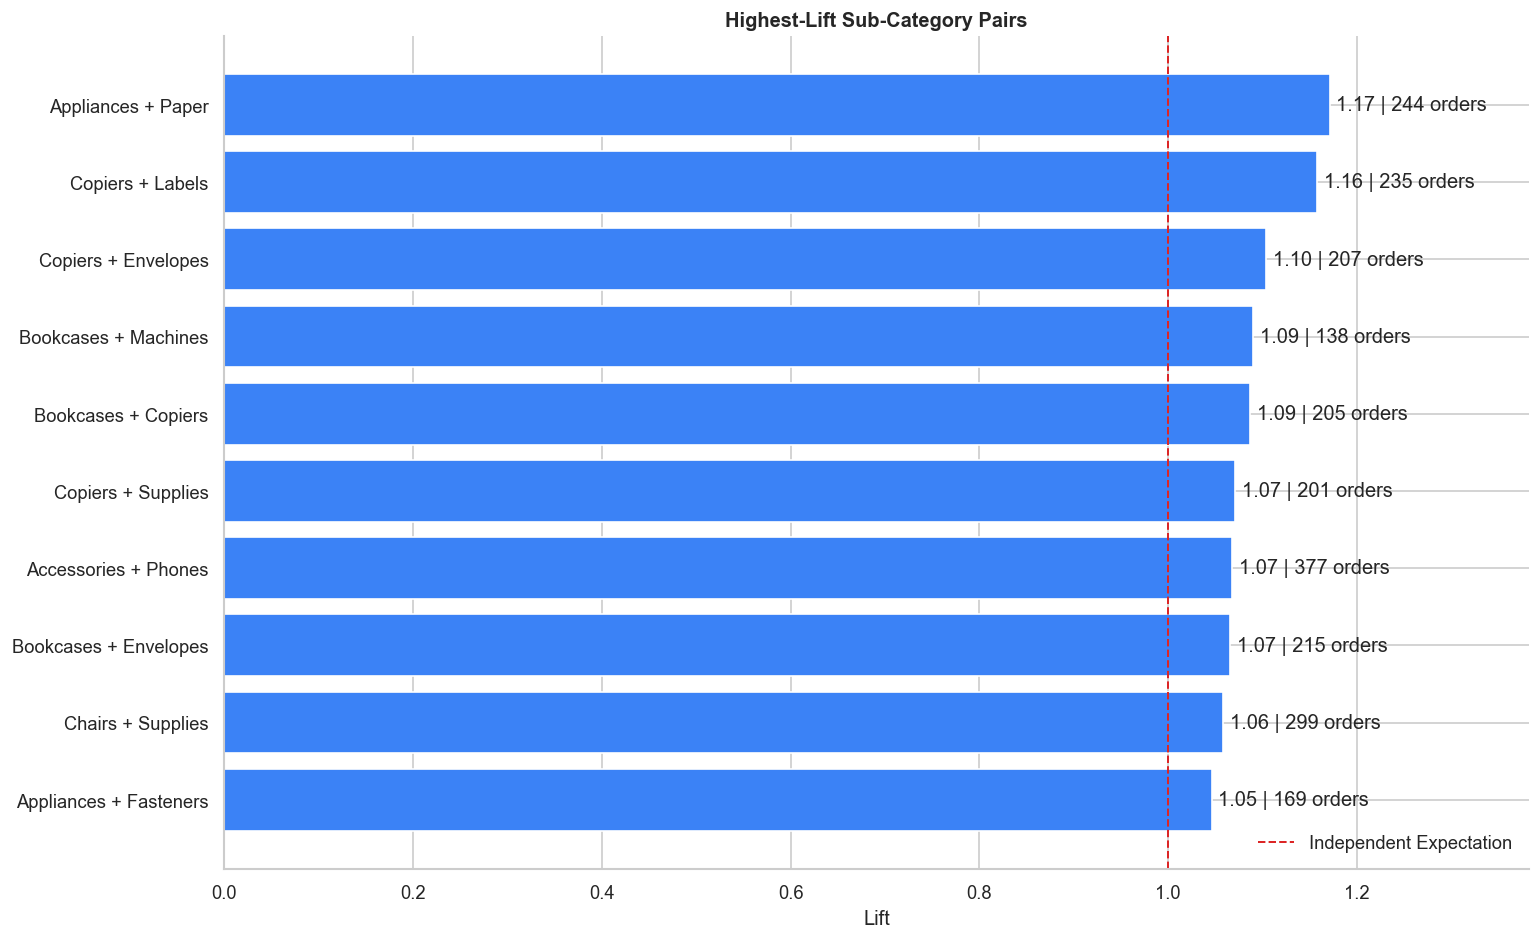

In [18]:
sub_category_lift_chart = (
    high_lift_sub_category_pairs
    .sort_values("lift", ascending=True)
    .copy()
)

sub_category_lift_chart["pair_label"] = (
    sub_category_lift_chart["sub_category_a"]
    + " + "
    + sub_category_lift_chart["sub_category_b"]
)


fig, axis = plt.subplots(figsize=(13, 8))

lift_bars = axis.barh(
    sub_category_lift_chart["pair_label"],
    sub_category_lift_chart["lift"],
    color="#3B82F6"
)

axis.axvline(
    1,
    color="#DC2626",
    linestyle="--",
    linewidth=1.2,
    label="Independent Expectation"
)

axis.set_title(
    "Highest-Lift Sub-Category Pairs"
)
axis.set_xlabel("Lift")
axis.set_ylabel("")

axis.bar_label(
    lift_bars,
    labels=[
        (
            f"{lift:.2f} | "
            f"{pair_orders} orders"
        )
        for lift, pair_orders in zip(
            sub_category_lift_chart["lift"],
            sub_category_lift_chart[
                "pair_order_count"
            ]
        )
    ],
    padding=4
)

axis.margins(x=0.18)

axis.legend(
    frameon=False
)

sns.despine()
plt.tight_layout()
plt.show()

### Product Combination Findings

- **49.66% of analytical orders** contained multiple unique products.
- Exact product-level combinations were extremely sparse: the maximum pair frequency was only three orders.
- Product-level lift values were therefore not treated as reliable evidence for bundling decisions.
- At the sub-category level, **47.53% of orders** contained multiple sub-categories and all 136 possible sub-category pairs were observed.
- The most frequent pair was **Binders + Storage**, appearing in 895 orders, but its lift of **0.93** indicated popularity rather than positive affinity.
- Among pairs with at least 50 co-orders, 27 recorded lift above 1.
- **Appliances + Paper** achieved the highest eligible lift at **1.17**, with 244 pair orders.
- **Copiers + Labels** followed with a lift of **1.16** and 235 pair orders.
- **Accessories + Phones** combined relatively strong evidence volume of 377 pair orders with a positive lift of **1.07**.

**Business implication:** Sub-category pairs with both positive lift and meaningful order volume are suitable candidates for controlled cross-sell experiments. The modest lift values support testing rather than immediate permanent bundling.

**Limitations:** Co-occurrence does not show purchase sequence, customer intent, or incremental campaign impact. Support, confidence, and lift measure association rather than causation.

## 8. Advanced Analysis Validation

I validate the statistical inputs, effect sizes, cohort calculations, and basket-analysis metrics before documenting the final conclusions.

In [19]:
advanced_validation_checks = pd.DataFrame({
    "Validation Check": [
        "Statistical row count preserved",
        "Row ID remains unique",
        "No missing statistical variables",
        "All discount bands assigned",
        "Discount contingency total reconciles",
        "Spearman result is finite",
        "Spearman p-value is valid",
        "Cramer's V is between 0 and 1",
        "Discount epsilon-squared is between 0 and 1",
        "Product-level records reconcile",
        "Category epsilon-squared is between 0 and 1",
        "All three category comparisons completed",
        "Holm-adjusted p-values are valid",
        "Cohort sizes reconcile with customers",
        "Cohort indices are positive",
        "Cohort retention rates are valid",
        "Active customers do not exceed cohort size",
        "Order baskets reconcile with analytical orders",
        "Product-pair counts are positive",
        "Product-pair probabilities are valid",
        "Product-pair lift values are finite",
        "Sub-category baskets reconcile with orders",
        "Sub-category pair counts are positive",
        "Sub-category pair probabilities are valid",
        "Sub-category lift values are finite"
    ],
    "Passed": [
        len(statistical_data) == len(orders),
        orders["row_id"].is_unique,
        not statistical_data[
            [
                "discount",
                "profit",
                "line_profit_margin"
            ]
        ].isna().any().any(),
        statistical_data["discount_band"].notna().all(),
        (
            discount_loss_table["Total Lines"].sum()
            == len(statistical_data)
        ),
        np.isfinite(spearman_rho),
        0 <= spearman_p_value <= 1,
        0 <= cramers_v <= 1,
        0 <= epsilon_squared <= 1,
        (
            len(product_statistical_data)
            == orders["product_id"].nunique()
        ),
        0 <= category_epsilon_squared <= 1,
        len(pairwise_category_results) == 3,
        pairwise_category_results[
            "Holm Adjusted P-Value"
        ].between(0, 1).all(),
        (
            cohort_sizes["cohort_size"].sum()
            == orders["customer_key"].nunique()
        ),
        cohort_activity["cohort_index"].ge(1).all(),
        cohort_activity["retention_rate"].between(
            0,
            1
        ).all(),
        (
            cohort_activity["active_customers"]
            <= cohort_activity["cohort_size"]
        ).all(),
        (
            len(order_baskets)
            == orders["order_key"].nunique()
        ),
        product_pair_metrics[
            "pair_order_count"
        ].gt(0).all(),
        (
            product_pair_metrics["support"].between(
                0,
                1
            ).all()
            and product_pair_metrics[
                "confidence_a_to_b"
            ].between(0, 1).all()
            and product_pair_metrics[
                "confidence_b_to_a"
            ].between(0, 1).all()
        ),
        (
            np.isfinite(
                product_pair_metrics["lift"]
            ).all()
            and product_pair_metrics["lift"].gt(0).all()
        ),
        (
            len(sub_category_baskets)
            == orders["order_key"].nunique()
        ),
        sub_category_pair_metrics[
            "pair_order_count"
        ].gt(0).all(),
        (
            sub_category_pair_metrics[
                "support"
            ].between(0, 1).all()
            and sub_category_pair_metrics[
                "confidence_a_to_b"
            ].between(0, 1).all()
            and sub_category_pair_metrics[
                "confidence_b_to_a"
            ].between(0, 1).all()
        ),
        (
            np.isfinite(
                sub_category_pair_metrics["lift"]
            ).all()
            and sub_category_pair_metrics[
                "lift"
            ].gt(0).all()
        )
    ]
})

display(advanced_validation_checks)

print(
    "All advanced-analysis validations passed:",
    advanced_validation_checks["Passed"].all()
)

,Validation Check,Passed
0,Statistical row count preserved,True
1,Row ID remains unique,True
2,No missing statistical variables,True
3,All discount bands assigned,True
4,Discount contingency total reconciles,True
5,Spearman result is finite,True
6,Spearman p-value is valid,True
7,Cramer's V is between 0 and 1,True
8,Discount epsilon-squared is between 0 and 1,True
9,Product-level records reconcile,True


All advanced-analysis validations passed: True


## 9. Executive Statistical Summary

### Evidence-Based Conclusions

1. Discount and line profit margin had a **strong negative Spearman correlation of -0.6691**.
2. Discount band and loss status had a **large association**, with **Cramér's V = 0.8393**.
3. Profit-margin distributions differed significantly across discount bands, with a **large ε² effect of 0.5020**.
4. Median line margin declined from **27.00% without discount** to **-4.29% at 20%–30% discount** and **-55.52% above 30% discount**.
5. Product-level profitability differed significantly across categories, with a **moderate ε² effect of 0.0734**.
6. Furniture had the lowest median product margin at **9.04%**. Its largest pairwise difference was against Office Supplies, with a **moderate rank-biserial effect of -0.3735**.
7. The Month-2 weighted retention rate was **28.19%**, while Month-12 activity retention was **38.35%**. Later recovery confirms that customers can return after inactive months.
8. Exact product-pair evidence was too sparse for reliable bundle recommendations: the maximum pair frequency was only three orders.
9. Sub-category analysis provided stronger evidence. **Appliances + Paper** had the highest eligible lift at **1.17**, while **Accessories + Phones** combined positive lift with 377 pair orders.
10. All 25 advanced-analysis validation checks passed successfully.

### Management Priorities

- Introduce stronger profitability controls for discounts above 20%, especially above 30%.
- Review Furniture pricing, discounts, and product portfolio beyond the Tables sub-category.
- Test early post-purchase engagement to address the Month-2 activity decline.
- Use reactivation strategies because customer activity can recover after inactive months.
- Pilot selected sub-category cross-sell combinations and measure incremental results before permanent rollout.
- Avoid exact product-level bundle decisions until more transaction history is available.

### Analytical Limitations

- Statistical association does not prove causation.
- Sales lines within the same order may not be fully independent.
- Cohorts represent first observed purchase within the dataset, not confirmed first-ever acquisition.
- Small acquisition cohorts were excluded from the comparative retention heatmap.
- Exact product pairs were highly sparse, and sub-category lifts were modest.
- Market-basket metrics do not measure purchase sequence, intent, or incremental campaign impact.